# Automatização em Python da Alocação de Geradores Fotovoltaicos para Estudos na Rede Elétrica com o OpenDSS

**Orientador:** Prof. Dr. Lucas Silveira Melo  
**Co-autores:**
- Ruth Pastora Saraiva Leão
- Raquel Cristina Filiagi Gregory
- Janaína Barbosa Almada
- Luis Felipe Carneiro de Souza
- Caio Lucas Nascimento Silva

---

### Metodologia e Estrutura deste Notebook (Gráficos Individuais Padronizados para Banner)
1. **Simulações Paramétricas Independentes (`scenarios/run_penetration_scenarios.py`)**: As co-simulações temporais completas de 24 horas (288 passos de 5 minutos) no Mosaik + OpenDSS foram previamente executadas para cada nível de penetração nas 906 barras elegíveis do alimentador **IEEE European LV Test Feeder (`LVTestCase`)**:
   - **Cenário Base (0% de penetração / 0 PVs)**: Rede BT puramente passiva com 55 cargas residenciais.
   - **Cenários de Penetração FV (2%, 5%, 8% e 10% da rede)**: Alocação automatizada via `PVCreator` (dimensionamento comercial ANEEL + séries climáticas do BR-PVGen interpoladas via PCHIP para 5 min).
2. **Destaque Central ao Pior Caso Operativo (10% da Rede — 91 PVs / 470,7 kVA — Monofásicos BT)**:
   - A análise enfatiza o **Pior Caso Operativo (10% de penetração)** frente à rede sem geração (**0%**), evidenciando os fenômenos de elevação de tensão (*voltage rise*), conformidade com os limites do PRODIST Módulo 8 (ANEEL) e fluxo reverso de potência.
3. **Desmembramento das Figuras em Gráficos Individuais**:
   - Todos os gráficos foram individualizados (uma figura/arquivo por gráfico), permitindo diagramação modular no banner acadêmico.
4. **Controle Manual Centralizado das Proporções**:
   - Uma célula no início do notebook define as variáveis `LARGURA_FIGURA` e `ALTURA_FIGURA`, garantindo que **todos os gráficos tenham exatamente as mesmas dimensões e proporções padronizadas**.

In [1]:
import json
import os
import re
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.interpolate import PchipInterpolator

# Identifica o diretório raiz do projeto de forma robusta
_cwd = Path.cwd()
if _cwd.name == "notebooks":
    PROJECT_ROOT = _cwd.parent.resolve()
else:
    PROJECT_ROOT = _cwd.resolve()

if not (PROJECT_ROOT / "data" / "LVTestCase").exists():
    for parent in [_cwd] + list(_cwd.parents):
        if (parent / "data" / "LVTestCase").exists():
            PROJECT_ROOT = parent.resolve()
            break

os.chdir(PROJECT_ROOT)

DATA_DIR = (PROJECT_ROOT / "data" / "LVTestCase").resolve()
INFOPV_DIR = (PROJECT_ROOT / "data" / "InfoPV").resolve()
OUTPUT_DIR = (PROJECT_ROOT / "output").resolve()
BANNER_FIG_DIR = (OUTPUT_DIR / "figuras_banner").resolve()
BANNER_FIG_DIR.mkdir(parents=True, exist_ok=True)

# Paleta de cores de alto contraste para banner científico (Okabe-Ito / IEEE)
COLORS = {
    "navy": "#0B3C5D",
    "blue": "#1F77B4",
    "cyan": "#16A34A",
    "orange": "#E69F00",
    "red": "#D55E00",
    "crimson": "#B22222",
    "purple": "#CC79A7",
    "gray": "#666666",
    "lightgray": "#D9D9D9",
}


def salvar_figura_banner(fig, nome_base: str):
    # Salva a figura em PNG (500 DPI) e PDF vetorial para o banner
    caminho_png = BANNER_FIG_DIR / f"{nome_base}.png"
    caminho_pdf = BANNER_FIG_DIR / f"{nome_base}.pdf"
    fig.savefig(caminho_png, dpi=500, bbox_inches="tight")
    fig.savefig(caminho_pdf, bbox_inches="tight")
    print(f"[OK] Figura exportada:\n  -> {caminho_png}\n  -> {caminho_pdf}")


print(f"Diretório raiz do projeto : {PROJECT_ROOT}")
print(f"Figuras para o banner em  : {BANNER_FIG_DIR}")

Diretório raiz do projeto : /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator
Figuras para o banner em  : /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner


In [2]:
# ==============================================================================
# CONTROLE MANUAL DAS DIMENSÕES E PROPORÇÕES DE TODOS OS GRÁFICOS
# Altere os valores abaixo para ajustar a largura e altura uniformemente em todas as figuras:
# ==============================================================================
LARGURA_FIGURA = 9.5    # Largura em polegadas (ex: 8.5, 9.5, 10.5, 12.0)
ALTURA_FIGURA = 6.2     # Altura em polegadas (ex: 5.5, 6.2, 7.0, 8.0)
TAMANHO_PADRAO = (LARGURA_FIGURA, ALTURA_FIGURA)

# Configuração visual global do Matplotlib para publicação em Banner (500 DPI)
plt.rcParams.update(
    {
        "figure.figsize": TAMANHO_PADRAO,
        "figure.dpi": 120,
        "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.15,
        "font.family": "sans-serif",
        "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
        "font.size": 13,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 13,
        "axes.labelweight": "bold",
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 10.5,
        "legend.frameon": True,
        "legend.framealpha": 0.92,
        "legend.edgecolor": "#CCCCCC",
        "axes.grid": True,
        "grid.linestyle": "--",
        "grid.alpha": 0.45,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

print(f"[CONFIG] Dimensão padrão aplicada a todos os gráficos: {LARGURA_FIGURA} x {ALTURA_FIGURA} polegadas ({TAMANHO_PADRAO})")

[CONFIG] Dimensão padrão aplicada a todos os gráficos: 9.5 x 6.2 polegadas ((9.5, 6.2))


## 1. Carregamento dos Resultados Pré-Simulados da Co-simulação Mosaik + OpenDSS

Lemos a tabela resumo dos cenários executados (`output/tabela_cenarios_penetracao.csv`) e importamos os datasets temporais de 24 horas gerados pelo `Collector` (`output/result_penetracao_{pct}pct.csv`) para os níveis de penetração:
- **0% (Cenário Base — Sem FV)**: $N_{\text{PV}} = 0$ geradores, potência $0{,}0\text{ kVA}$.
- **2% da rede**: $N_{\text{PV}} = 18$ geradores, potência $86{,}5\text{ kVA}$.
- **5% da rede**: $N_{\text{PV}} = 45$ geradores, potência $228{,}2\text{ kVA}$.
- **8% da rede**: $N_{\text{PV}} = 72$ geradores, potência $396{,}9\text{ kVA}$.
- **10% da rede (Pior Caso Operativo)**: $N_{\text{PV}} = 91$ geradores, potência $470{,}7\text{ kVA}$ (monofásicos BT).

In [3]:
# 1. Carrega tabela resumo de cenários
df_cenarios = pd.read_csv(OUTPUT_DIR / "tabela_cenarios_penetracao.csv")
print("Cenários de Penetração Fotovoltaica Registrados:")
display(df_cenarios)

# 2. Carrega datasets temporais de cada cenário e extrai variáveis físicas
niveis_pct = [0, 2, 5, 8, 10]
dados_cenarios = {}

for pct in niveis_pct:
    csv_path = OUTPUT_DIR / f"result_penetracao_{pct}pct.csv"
    if not csv_path.exists():
        raise FileNotFoundError(f"Arquivo {csv_path} não encontrado! Execute run_penetration_scenarios.py primeiro.")
    
    df_raw = pd.read_csv(csv_path, parse_dates=["date"])
    
    # Extrai fluxo de potência ativa no alimentador principal LINE1
    cols_line1 = [c for c in df_raw.columns if "line1-P" in c]
    p_feeder = df_raw[cols_line1].sum(axis=1) if cols_line1 else pd.Series(0.0, index=df_raw.index)
    # Validação física (filtra eventuais passos de não-convergência numérica extrema)
    p_feeder[p_feeder.abs() > 4000] = np.nan
    p_feeder = p_feeder.interpolate().bfill().ffill()
    
    # Extrai colunas de tensão das barras BT (exclui sourcebus de média tensão)
    v_cols = [c for c in df_raw.columns if c.endswith(("V1_pu", "V2_pu", "V3_pu")) and "sourcebus" not in c.lower()]
    v_df = df_raw[v_cols].copy()
    v_df[(v_df < 0.5) | (v_df > 2.5)] = np.nan
    v_df = v_df.interpolate().bfill().ffill()
    
    # Extrai geração ativa FV injetada pelo simulador de inversores
    pac_cols = [c for c in df_raw.columns if c.endswith("-P_ac")]
    p_pv_total = df_raw[pac_cols].sum(axis=1) if pac_cols else pd.Series(0.0, index=df_raw.index)
    
    # Mapeamento barra a barra no horário de pico solar (passo 150 -> 12h30)
    passo_pico = 150
    v_bus_pico = {}
    for col in v_cols:
        m = re.search(r"Bus-([0-9]+)-V", col)
        if m:
            b_id = m.group(1)
            v_val = float(v_df.iloc[passo_pico][col])
            v_bus_pico.setdefault(b_id, []).append(v_val)
    # Média entre fases da barra no pico
    v_bus_pico_media = {b: float(np.mean(vals)) for b, vals in v_bus_pico.items()}
    
    # Tensão na barra crítica e fase mais afetada da rede (Barra 890, Fase 2)
    cols_890_v2 = [c for c in v_cols if "Bus-890-V2" in c]
    v_bus890_v2 = v_df[cols_890_v2[0]] if cols_890_v2 else pd.Series(np.nan, index=df_raw.index)
    
    # Tensão na barra 699 (mantida para histórico e compatibilidade)
    cols_699 = [c for c in v_cols if "Bus-699-V" in c]
    v_bus699 = v_df[cols_699].mean(axis=1) if cols_699 else pd.Series(np.nan, index=df_raw.index)
    
    dados_cenarios[pct] = {
        "df": df_raw,
        "date": df_raw["date"],
        "P_feeder_kW": p_feeder,
        "P_pv_total_kW": p_pv_total,
        "v_max_t": v_df.max(axis=1),
        "v_min_t": v_df.min(axis=1),
        "v_mean_t": v_df.mean(axis=1),
        "v_p95_t": v_df.quantile(0.95, axis=1),
        "v_bus890_v2_t": v_bus890_v2,
        "v_bus699_t": v_bus699,
        "v_bus_pico": v_bus_pico_media,
    }

timeline_24h = pd.to_datetime(dados_cenarios[0]["date"])
print(f"\n[OK] Todos os {len(niveis_pct)} cenários foram carregados e validados com sucesso!")

Cenários de Penetração Fotovoltaica Registrados:


,pct_alvo,pct_efetivo,qtd_pvs,kva_total,arquivo_csv,tempo_simulacao_s
0,0,0.00,0,0.0,output/result_penetracao_0pct.csv,13.49
1,2,1.99,18,86.5,output/result_penetracao_2pct.csv,17.94
2,5,4.97,45,228.2,output/result_penetracao_5pct.csv,18.17
3,8,7.95,72,396.9,output/result_penetracao_8pct.csv,20.86
4,10,10.04,91,470.7,output/result_penetracao_10pct.csv,23.04



[OK] Todos os 5 cenários foram carregados e validados com sucesso!


## 2. Metadados dos Geradores FV Alocados pelo `PVCreator` (Pior Caso: 10% da Rede — 91 PVs)

Extraímos os parâmetros técnicos do script OpenDSS ativo (`data/LVTestCase/LVTestCase_pv.dss`), que modela o **Pior Caso Operativo (10% de penetração na rede)** com **91 sistemas fotovoltaicos** alocados (`my_seed=25`), totalizando **$470{,}7\text{ kVA}$** de capacidade instalada estritamente monofásica BT ($1{,}0$ a $10{,}0\text{ kVA}$).

In [4]:
# Extrai a lista de sistemas fotovoltaicos alocados a partir do arquivo DSS
pv_dss_lines = (DATA_DIR / "LVTestCase_pv.dss").read_text(encoding="utf-8").split("\n")
pvs_metadata = []

for line in pv_dss_lines:
    if line.strip().startswith("New PVSystem."):
        m = re.search(
            r"New PVSystem\.(\w+)\s+phases=(\d+)\s+Bus1=([\d\.]+)\s+kV=([\d\.]+)\s+kVA=([\d\.]+).*Pmpp=([\d\.]+)",
            line,
        )
        if m:
            pvs_metadata.append(
                {
                    "Nome": m.group(1),
                    "Fases": int(m.group(2)),
                    "Barra_Completa": m.group(3),
                    "Barra": m.group(3).split(".")[0],
                    "kV_Nominal": float(m.group(4)),
                    "Potencia_kVA": float(m.group(5)),
                    "Pmpp_kW": float(m.group(6)),
                }
            )

df_pvs = pd.DataFrame(pvs_metadata)

TOTAL_BARRAS_REDE = 906
pct_efetivo = (len(df_pvs) / TOTAL_BARRAS_REDE) * 100.0

print("=" * 82)
print("RESUMO DOS GERADORES FV ALOCADOS PELO PVCREATOR (PIOR CASO: 10% DA REDE)")
print("=" * 82)
print(f"Total de barras elegíveis da rede : {TOTAL_BARRAS_REDE} barras")
print(f"Taxa de penetração efetiva        : {pct_efetivo:.2f}% da rede")
print(f"Quantidade de geradores FV        : {len(df_pvs)} unidades")
print(f"Capacidade instalada total        : {df_pvs['Potencia_kVA'].sum():.1f} kVA")
print(f"Potência nominal média            : {df_pvs['Potencia_kVA'].mean():.2f} kVA")
print(f"Faixa comercial de inversores     : {df_pvs['Potencia_kVA'].min():.1f} kVA a {df_pvs['Potencia_kVA'].max():.1f} kVA")
display(df_pvs.head(10))

RESUMO DOS GERADORES FV ALOCADOS PELO PVCREATOR (PIOR CASO: 10% DA REDE)
Total de barras elegíveis da rede : 906 barras
Taxa de penetração efetiva        : 10.04% da rede
Quantidade de geradores FV        : 91 unidades
Capacidade instalada total        : 470.7 kVA
Potência nominal média            : 5.17 kVA
Faixa comercial de inversores     : 1.0 kVA a 10.0 kVA


,Nome,Fases,Barra_Completa,Barra,kV_Nominal,Potencia_kVA,Pmpp_kW
0,PV1,1,466.2,466,0.24,4.0,4.0
1,PV2,1,197.1,197,0.24,8.0,8.0
2,PV3,1,725.3,725,0.24,2.0,2.0
3,PV4,1,666.3,666,0.24,2.0,2.0
4,PV5,1,180.3,180,0.24,3.0,3.0
5,PV6,1,62.2,62,0.24,7.5,7.5
6,PV7,1,699.3,699,0.24,6.0,6.0
7,PV8,1,191.2,191,0.24,5.0,5.0
8,PV9,1,521.2,521,0.24,3.0,3.0
9,PV10,1,876.3,876,0.24,8.0,8.0


## 3. Figura 1a — Topologia Georreferenciada da Rede IEEE LV Test Case (Pior Caso: 10% FV)

Mapa espacial completo do alimentador de baixa tensão:
- **906 barras elegíveis**, **905 trechos de linha** e **55 cargas residenciais**.
- Dispersão geográfica dos **91 geradores fotovoltaicos alocados no Pior Caso (10% da rede)**, em círculos de tamanho pequeno padronizado, coloridos pela sua potência nominal (kVA), com destaque para a subestação abaixadora TR1 (800 kVA).

[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig1a_topologia_rede_pior_caso.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig1a_topologia_rede_pior_caso.pdf


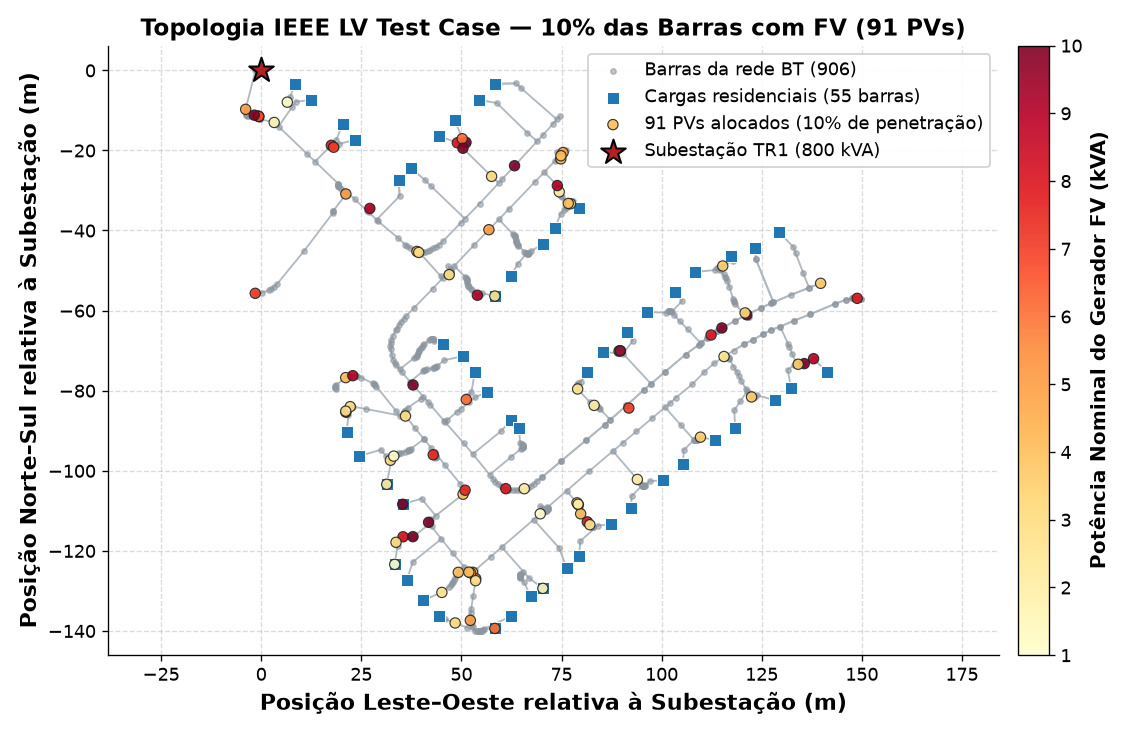

In [5]:
# 1. Carrega coordenadas geográficas das barras (Buscoords.txt)
df_coords = pd.read_csv(
    DATA_DIR / "Buscoords.txt",
    sep=r"\s+",
    header=None,
    names=["Bus", "X", "Y"],
    dtype={"Bus": str, "X": float, "Y": float},
)
x0, y0 = df_coords.loc[df_coords["Bus"] == "1", ["X", "Y"]].values[0]
df_coords["X_m"] = df_coords["X"] - x0
df_coords["Y_m"] = df_coords["Y"] - y0
df_coords["Dist_Sub_m"] = np.hypot(df_coords["X_m"], df_coords["Y_m"])
coords_map = df_coords.set_index("Bus")[["X_m", "Y_m", "Dist_Sub_m"]].to_dict("index")

# 2. Carrega segmentos de linha e barras de carga a partir dos arquivos do circuito
line_segments = []
for l in (DATA_DIR / "Lines.txt").read_text(encoding="utf-8").split("\n"):
    m = re.search(r"Bus1=([\w\.]+)\s+Bus2=([\w\.]+)", l)
    if m:
        b1, b2 = m.group(1).split(".")[0], m.group(2).split(".")[0]
        if b1 in coords_map and b2 in coords_map:
            line_segments.append(
                (
                    (coords_map[b1]["X_m"], coords_map[b2]["X_m"]),
                    (coords_map[b1]["Y_m"], coords_map[b2]["Y_m"]),
                )
            )

load_buses_set = set()
for l in (DATA_DIR / "Loads.txt").read_text(encoding="utf-8").split("\n"):
    m = re.search(r"Bus1=([\w\.]+)", l)
    if m:
        load_buses_set.add(m.group(1).split(".")[0])

# Associa coordenadas ao DataFrame de PVs
df_pvs["X_m"] = df_pvs["Barra"].map(lambda b: coords_map.get(b, {}).get("X_m", np.nan))
df_pvs["Y_m"] = df_pvs["Barra"].map(lambda b: coords_map.get(b, {}).get("Y_m", np.nan))
df_pvs["Dist_Sub_m"] = df_pvs["Barra"].map(lambda b: coords_map.get(b, {}).get("Dist_Sub_m", np.nan))

# 3. Construção da Figura 1a (Individual com tamanho padrão)
fig, ax = plt.subplots(figsize=TAMANHO_PADRAO)

for xs, ys in line_segments:
    ax.plot(xs, ys, color="#B0B8C1", linewidth=1.1, zorder=1)

# Barras comuns da rede BT
ax.scatter(
    df_coords["X_m"],
    df_coords["Y_m"],
    s=10,
    color="#8C96A0",
    alpha=0.55,
    label=f"Barras da rede BT ({TOTAL_BARRAS_REDE})",
    zorder=2,
)

# Barras com cargas residenciais
df_load_coords = df_coords[df_coords["Bus"].isin(load_buses_set)]
ax.scatter(
    df_load_coords["X_m"],
    df_load_coords["Y_m"],
    s=44,
    marker="s",
    color=COLORS["blue"],
    edgecolor="white",
    linewidth=0.6,
    label=f"Cargas residenciais ({len(df_load_coords)} barras)",
    zorder=3,
)

# Geradores FV alocados (círculos de tamanho uniforme pequeno e semitransparentes, coloridos por kVA)
sc_pv = ax.scatter(
    df_pvs["X_m"],
    df_pvs["Y_m"],
    s=38,
    c=df_pvs["Potencia_kVA"],
    cmap="YlOrRd",
    edgecolor="#222222",
    linewidth=0.7,
    alpha=0.9,
    zorder=4,
    label=f"91 PVs alocados (10% de penetração)",
)

# Subestação (Barra 1)
ax.scatter(
    [0],
    [0],
    s=240,
    marker="*",
    color=COLORS["crimson"],
    edgecolor="black",
    linewidth=1.2,
    zorder=5,
    label="Subestação TR1 (800 kVA)",
)

cbar = plt.colorbar(sc_pv, ax=ax, pad=0.02, fraction=0.045)
cbar.set_label("Potência Nominal do Gerador FV (kVA)", fontsize=12, fontweight="bold")

ax.set_title("Topologia IEEE LV Test Case — 10% das Barras com FV (91 PVs)")
ax.set_xlabel("Posição Leste–Oeste relativa à Subestação (m)")
ax.set_ylabel("Posição Norte–Sul relativa à Subestação (m)")
ax.legend(loc="upper right", frameon=True)
ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()
salvar_figura_banner(fig, "fig1a_topologia_rede_pior_caso")
plt.show()

## 4. Figura 1b e Tabela Complementar — Distribuição dos Geradores FV por Fração da Potência Instalada

Gráfico de rosca concêntrica dupla e tabela analítica dividindo os geradores por faixas de potência comercial dimensionadas para obter a **divisão mais homogênea e equilibrada possível da capacidade instalada total** ($470{,}7\text{ kVA}$):

### Estudo Comparativo do Número de Grupos ($K$):
A análise estatística dos 14 portes comerciais de inversores monofásicos alocados ($1{,}0$ a $10{,}0\text{ kVA}$) demonstrou que a divisão em **$K=4$ faixas de potência (quartis)** é a melhor distribuída:
- **$K=3$ grupos**: Desvio-padrão de $16{,}45\text{ kVA}$ ($CV = 10{,}5\%$, alvo $33{,}3\%$ por grupo).
- **$K=4$ grupos (Ótimo)**: Menor desvio-padrão da potência ($10{,}11\text{ kVA}$, $CV = \mathbf{8{,}6\%}$, alvo $25{,}0\%$ por quartil).
- **$K=5$ grupos**: Desvio-padrão de $20{,}14\text{ kVA}$ ($CV = 21{,}4\%$, mais do que o dobro da variabilidade de $K=4$).
- **$K=6$ grupos**: Desvio-padrão de $26{,}59\text{ kVA}$ ($CV = 33{,}9\%$).

> **Fundamentação Física da Escolha de 4 Faixas**:  
> Os 13 geradores de $10\text{ kVA}$ somam sozinhos $130{,}0\text{ kVA}$ ($27{,}62\%$ da potência total). Por serem unidades discretas indivisíveis, qualquer divisão com 5 ou mais faixas (alvo $\le 20\%$) gera assimetria forçada. Com $K=4$, cada faixa responde por aproximadamente um quarto da capacidade total ($21{,}9\%$ a $27{,}6\%$).

### Tabela Síntese da Distribuição por Faixas Comerciais (Quartis de Potência):
| Faixa Comercial (kVA) | Potência Total (kVA) | Fração Potência (%) | Qtd. Geradores | Fração Unidades (%) |
| :--- | :---: | :---: | :---: | :---: |
| **1,0 a 3,6 kVA** | 103,2 | 21,9% | 41 PVs | 45,1% |
| **4,0 a 7,0 kVA** | 114,0 | 24,2% | 22 PVs | 24,2% |
| **7,5 a 9,0 kVA** | 123,5 | 26,2% | 15 PVs | 16,5% |
| **10,0 kVA** | 130,0 | 27,6% | 13 PVs | 14,3% |
| **Total** | **470,7** | **100,0%** | **91 PVs** | **100,0%** |

[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig1b_portes_comerciais_pv.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig1b_portes_comerciais_pv.pdf


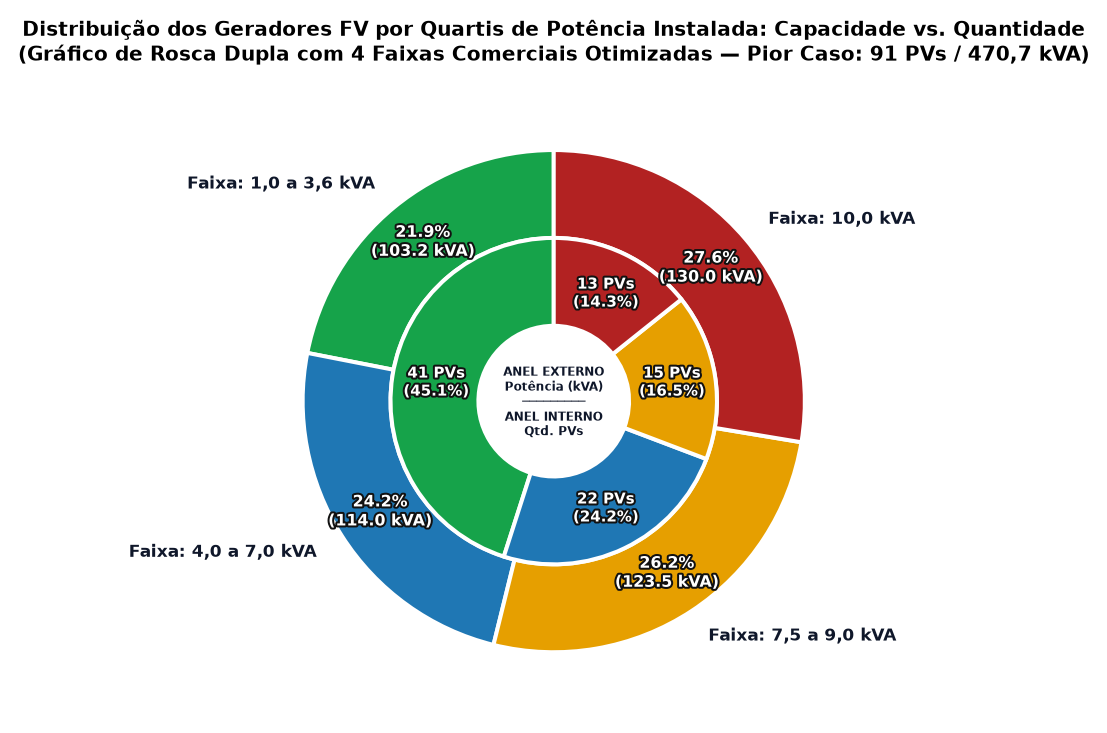

TABELA COMPLEMENTAR — DISTRIBUIÇÃO DOS GERADORES FV POR FAIXAS DE POTÊNCIA (FIGURA 1B)


,Faixa Comercial (kVA),Capacidade Total (kVA),Fração da Potência (%),Qtd. Geradores (unidades),Fração de Geradores (%)
0,"1,0 a 3,6 kVA",103.2,21.9%,41,45.1%
1,"4,0 a 7,0 kVA",114.0,24.2%,22,24.2%
2,"7,5 a 9,0 kVA",123.5,26.2%,15,16.5%
3,"10,0 kVA",130.0,27.6%,13,14.3%
4,Total,470.7,"100,0%",91,"100,0%"



Tabela salva em:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/tabela_portes_comerciais_pv.csv


[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/tab1b_portes_comerciais_pv.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/tab1b_portes_comerciais_pv.pdf


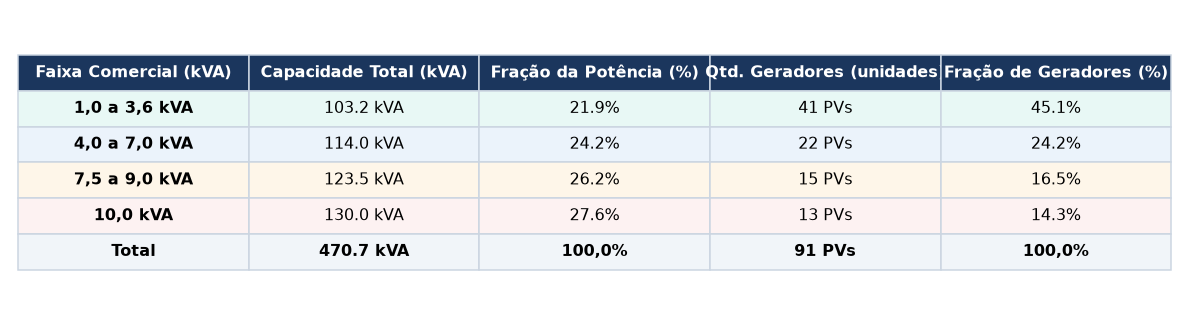

In [6]:
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe

fig, ax = plt.subplots(figsize=TAMANHO_PADRAO)

# Classificação das potências nas 4 faixas comerciais otimizadas por fração da potência total
def classificar_faixa(kva):
    if kva <= 3.6:
        return "1,0 a 3,6 kVA"
    elif kva <= 7.0:
        return "4,0 a 7,0 kVA"
    elif kva <= 9.0:
        return "7,5 a 9,0 kVA"
    else:
        return "10,0 kVA"

df_pvs["Faixa_Comercial"] = df_pvs["Potencia_kVA"].apply(classificar_faixa)

ordem_faixas = [
    "1,0 a 3,6 kVA",
    "4,0 a 7,0 kVA",
    "7,5 a 9,0 kVA",
    "10,0 kVA",
]

df_bivariada = df_pvs.groupby("Faixa_Comercial").agg(
    Potencia_Total_kVA=("Potencia_kVA", "sum"),
    Qtd_PVs=("Barra", "count"),
).reindex(ordem_faixas)

total_kva = df_bivariada["Potencia_Total_kVA"].sum()  # 470,7 kVA = 100%
total_pvs = df_bivariada["Qtd_PVs"].sum()              # 91 PVs = 100%

# Cores das 4 faixas comerciais (iguais para ambos os anéis)
cores_faixas = [
    COLORS["cyan"],
    COLORS["blue"],
    COLORS["orange"],
    COLORS["crimson"],
]

# Geometria com anéis alargados
r_out = 1.00
w_out = 0.35
r_in  = 0.65
w_in  = 0.35

# 1. Anel Externo: Potência Total Instalada (470,7 kVA = 100%)
wedges_out, texts_out, autotexts_out = ax.pie(
    df_bivariada["Potencia_Total_kVA"].values,
    radius=r_out,
    startangle=90,
    colors=cores_faixas,
    wedgeprops=dict(width=w_out, edgecolor="white", linewidth=2.4, antialiased=True),
    autopct=lambda pct: f"{pct:.1f}%\n({(pct * total_kva / 100.0):.1f} kVA)",
    pctdistance=0.82,
    labels=[f"Faixa: {faixa}" for faixa in df_bivariada.index],
    labeldistance=1.12,
    textprops=dict(fontsize=10.0, fontweight="bold", color="#0F172A"),
)

for autotext in autotexts_out:
    autotext.set_color("white")
    autotext.set_fontsize(9.5)
    autotext.set_fontweight("bold")
    autotext.set_path_effects([pe.withStroke(linewidth=2.4, foreground="#111111")])

# 2. Anel Interno: Quantidade de Geradores FV (91 PVs) com cores iguais e identificação de unidades e %
wedges_in, texts_in = ax.pie(
    df_bivariada["Qtd_PVs"].values,
    radius=r_in,
    startangle=90,
    colors=cores_faixas,
    wedgeprops=dict(width=w_in, edgecolor="white", linewidth=2.4, antialiased=True),
)

# Legendas do anel interno com a quantidade e percentual de unidades
for i, wedge in enumerate(wedges_in):
    qtd = df_bivariada["Qtd_PVs"].iloc[i]
    pct_pvs = (qtd / total_pvs) * 100.0
    ang = (wedge.theta2 - wedge.theta1) / 2.0 + wedge.theta1
    rad = np.deg2rad(ang)
    r_mid = r_in - (w_in / 2.0)
    x = r_mid * np.cos(rad)
    y = r_mid * np.sin(rad)
    ax.text(
        x,
        y,
        f"{qtd} PVs\n({pct_pvs:.1f}%)",
        ha="center",
        va="center",
        color="white",
        fontsize=9.0,
        fontweight="bold",
        path_effects=[pe.withStroke(linewidth=2.4, foreground="#111111")],
        zorder=10,
    )

# 3. Identificação no centro da rosca (ajustada e reduzida ao orifício central)
ax.text(
    0,
    0,
    "ANEL EXTERNO\nPotência (kVA)\n─────────\nANEL INTERNO\nQtd. PVs",
    ha="center",
    va="center",
    fontsize=7.2,
    fontweight="bold",
    color="#0F172A",
    linespacing=1.25,
)

ax.set_title(
    "Distribuição dos Geradores FV por Quartis de Potência Instalada: Capacidade vs. Quantidade\n(Gráfico de Rosca Dupla com 4 Faixas Comerciais Otimizadas — Pior Caso: 91 PVs / 470,7 kVA)",
    fontsize=12,
    fontweight="bold",
    pad=16,
)

plt.tight_layout()
salvar_figura_banner(fig, "fig1b_portes_comerciais_pv")
plt.show()

# ==============================================================================
# TABELA COMPLEMENTAR À FIGURA 1B: DISTRIBUIÇÃO CONSOLIDADA DOS GERADORES FV
# ==============================================================================
tabela_1b_dados = []
for f in ordem_faixas:
    row = df_bivariada.loc[f]
    pwr = row["Potencia_Total_kVA"]
    pvs = int(row["Qtd_PVs"])
    pct_pwr = (pwr / total_kva) * 100.0
    pct_pvs = (pvs / total_pvs) * 100.0
    tabela_1b_dados.append([
        f,
        f"{pwr:.1f}",
        f"{pct_pwr:.1f}%",
        pvs,
        f"{pct_pvs:.1f}%",
    ])

# Linha de totalização
tabela_1b_dados.append([
    "Total",
    f"{total_kva:.1f}",
    "100,0%",
    int(total_pvs),
    "100,0%",
])

colunas_1b = [
    "Faixa Comercial (kVA)",
    "Capacidade Total (kVA)",
    "Fração da Potência (%)",
    "Qtd. Geradores (unidades)",
    "Fração de Geradores (%)",
]

df_tabela_1b = pd.DataFrame(tabela_1b_dados, columns=colunas_1b)

# 1. Exportação em formato CSV
df_tabela_1b.to_csv(OUTPUT_DIR / "tabela_portes_comerciais_pv.csv", index=False, encoding="utf-8-sig")
df_tabela_1b.to_csv(BANNER_FIG_DIR / "tabela_portes_comerciais_pv.csv", index=False, encoding="utf-8-sig")

# 2. Exibição da tabela formatada no notebook
print("=" * 95)
print("TABELA COMPLEMENTAR — DISTRIBUIÇÃO DOS GERADORES FV POR FAIXAS DE POTÊNCIA (FIGURA 1B)")
print("=" * 95)
display(df_tabela_1b)
print(f"\nTabela salva em:\n  -> {BANNER_FIG_DIR / 'tabela_portes_comerciais_pv.csv'}")

# 3. Geração e exportação do cartão visual da tabela para o banner (PNG 600 DPI e PDF)
fig_tab, ax_tab = plt.subplots(figsize=(10.0, 2.8))
ax_tab.axis("off")

dados_visuais = [
    [f"{r[0]}", f"{r[1]} kVA", f"{r[2]}", f"{r[3]} PVs", f"{r[4]}"]
    for r in tabela_1b_dados
]

tab_visual = ax_tab.table(
    cellText=dados_visuais,
    colLabels=colunas_1b,
    cellLoc="center",
    loc="center",
)

tab_visual.auto_set_font_size(False)
tab_visual.set_fontsize(9.5)
tab_visual.scale(1.0, 1.6)

cores_linhas = ["#E8F8F5", "#EBF3FB", "#FEF6E9", "#FDF2F2", "#F1F5F9"]
for (r, c), cell in tab_visual.get_celld().items():
    cell.set_edgecolor("#CBD5E1")
    cell.set_linewidth(0.9)
    if r == 0:
        cell.set_facecolor("#1B365D")
        cell.set_text_props(color="white", fontweight="bold", fontsize=9.8)
    else:
        cell.set_facecolor(cores_linhas[r - 1])
        if r == len(tabela_1b_dados):
            cell.set_text_props(fontweight="bold")
        if c == 0:
            cell.set_text_props(fontweight="bold")

plt.tight_layout()
salvar_figura_banner(fig_tab, "tab1b_portes_comerciais_pv")
plt.show()

## 5. Figura 1c — Perfil Georreferenciado de Tensão nas 906 Barras no Pior Cenário (10% FV)

Mapa espacial completo do alimentador de baixa tensão capturado no **instante exato de maior tensão global da rede (12h45)**:
- **Hierarquia Visual e Diferenciação Geométrica**:
  - **Círculos menores (`o`)**: Barras da rede BT sem geração fotovoltaica (**815 barras**).
  - **Losangos menores (`D`)**: Barras com geradores fotovoltaicos alocados (**90 barras**).
  - **X em destaque (`X`) com borda branca**: **Barra Crítica 890**, onde ocorre a máxima elevação global de tensão da rede ($1{,}1333\text{ p.u.}$, associada ao gerador FV81 de 10 kVA na fase 2).
  - **Estrela (`*`)**: Subestação abaixadora TR1 fixada na origem $(0, 0\text{ m})$.
- **Representação Literal das Fases dos Condutores**:
  - **Trecho trifásico**: **3 linhas paralelas contínuas** (linhas triplas em `#475569`), traçadas ao longo dos 95 ramos contínuos do alimentador com afastamento transversal perceptível de $0{,}85\text{ m}$, permitindo visualizar individualmente cada condutor de fase da espinha dorsal da rede.
  - **Ramal monofásico**: **Linha única contínua** (em `#94A3B8`), representando com precisão as derivações monofásicas de entrada das unidades consumidoras (o alimentador não possui trechos bifásicos).
- **Métrica de Tensão nas Barras**: A cor de cada nó reflete a **tensão da fase mais crítica (máxima tensão entre as fases conectadas à barra)** no instante do pico ($1{,}0516\text{ p.u.}$ a $1{,}1333\text{ p.u.}$) utilizando a escala perceptiva `turbo`. Em redes BT com injeção monofásica desequilibrada, a fase com maior injeção solar apresenta a maior elevação pontual.
- **Topologia Limpa e Desobstruída**: Cargas e setas de anotação omitidas, com todos os elementos integrados na legenda com espaçamento vertical ampliado e símbolo de linha tripla customizado.

[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig1c_perfil_tensao_rede_pior_caso.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig1c_perfil_tensao_rede_pior_caso.pdf


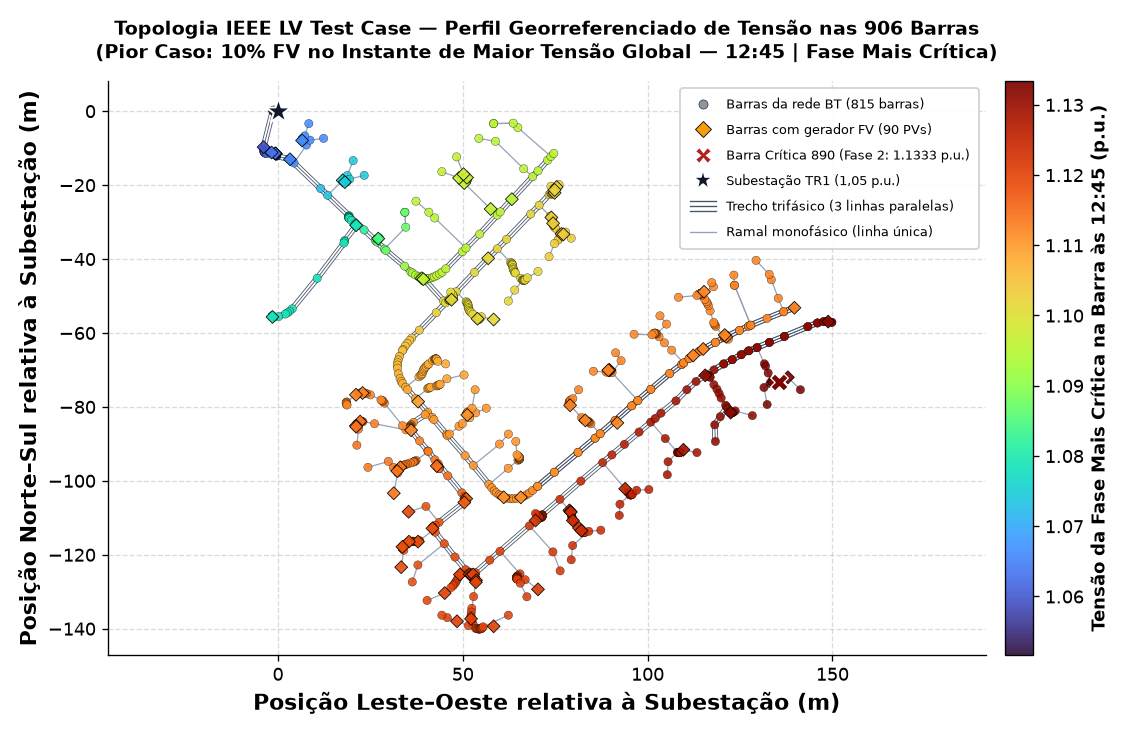

In [7]:
fig, ax = plt.subplots(figsize=TAMANHO_PADRAO)

# 1. Identificação das barras com geradores FV
pv_buses_set = set(df_pvs["Barra"].astype(str))

# 2. Localização do ponto e instante de maior tensão global na simulação
df10 = dados_cenarios[10]["df"]
v_cols10 = [
    c for c in df10.columns
    if c.endswith(("V1_pu", "V2_pu", "V3_pu")) and "sourcebus" not in c.lower()
]

# Coluna com o pico absoluto em toda a simulação
all_max_col = df10[v_cols10].max().idxmax()
v_max_global = float(df10[all_max_col].max())
step_pico_global = int(df10[all_max_col].idxmax())
t_pico_global = timeline_24h.iloc[step_pico_global].strftime("%H:%M")

m_crit = re.search(r"Bus-(\d+)-V(\d)", all_max_col)
barra_critica_id = m_crit.group(1)
fase_critica = m_crit.group(2)

bus_cols_map = {}
for c in v_cols10:
    m = re.search(r"Bus-(\d+)-V", c)
    if m:
        bus_cols_map.setdefault(m.group(1), []).append(c)

# Tensão da fase mais crítica de cada barra no instante do pico global
v_bus_at_peak = {
    b: float(df10.loc[step_pico_global, cols].max())
    for b, cols in bus_cols_map.items()
}
df_coords["V_pico_pu"] = df_coords["Bus"].map(v_bus_at_peak)
v_min_global = df_coords["V_pico_pu"].min()

# Categorização das barras
df_critica = df_coords[df_coords["Bus"] == barra_critica_id]
df_pv_outros = df_coords[(df_coords["Bus"].isin(pv_buses_set)) & (df_coords["Bus"] != barra_critica_id)]
df_normal = df_coords[~df_coords["Bus"].isin(pv_buses_set)]

# 3. Classificação dos condutores (trifásicos vs monofásicos)
edges_3ph = []
lines_1ph = []
for l in (DATA_DIR / "Lines.txt").read_text(encoding="utf-8").split("\n"):
    m = re.search(r"Bus1=([\w\.]+)\s+Bus2=([\w\.]+).*Linecode=([\w\._]+)", l)
    if m:
        b1, b2, lc = m.group(1).split(".")[0], m.group(2).split(".")[0], m.group(3)
        if b1 in coords_map and b2 in coords_map:
            n_phases = 3 if (lc.startswith("4c") or "SAC" in lc) else 1
            if n_phases == 3:
                edges_3ph.append((b1, b2))
            else:
                lines_1ph.append((coords_map[b1], coords_map[b2]))

# Decomposição do tronco trifásico em ramos contínuos para traçado perfeito das linhas triplas
adj_3ph = {}
for u, v in edges_3ph:
    adj_3ph.setdefault(u, set()).add(v)
    adj_3ph.setdefault(v, set()).add(u)

branch_nodes = {n for n, nbrs in adj_3ph.items() if len(nbrs) != 2}
visited_edges = set()
branches = []
for u, v in edges_3ph:
    e = tuple(sorted([u, v]))
    if e in visited_edges:
        continue
    path = [u, v]
    visited_edges.add(e)
    curr, prev = v, u
    while curr not in branch_nodes:
        nxt = [n for n in adj_3ph[curr] if n != prev][0]
        path.append(nxt)
        visited_edges.add(tuple(sorted([curr, nxt])))
        prev, curr = curr, nxt
    curr, prev = u, path[1]
    while curr not in branch_nodes:
        nxt = [n for n in adj_3ph[curr] if n != prev][0]
        path.insert(0, nxt)
        visited_edges.add(tuple(sorted([curr, nxt])))
        prev, curr = curr, nxt
    branches.append(path)

def get_branch_normals(pts):
    n = len(pts)
    normals = np.zeros_like(pts)
    for i in range(n):
        if i == 0:
            d = pts[1] - pts[0]
            L = np.hypot(d[0], d[1])
            normals[0] = np.array([-d[1], d[0]]) / max(L, 1e-6)
        elif i == n - 1:
            d = pts[-1] - pts[-2]
            L = np.hypot(d[0], d[1])
            normals[-1] = np.array([-d[1], d[0]]) / max(L, 1e-6)
        else:
            d1 = pts[i] - pts[i-1]
            d2 = pts[i+1] - pts[i]
            l1, l2 = np.hypot(d1[0], d1[1]), np.hypot(d2[0], d2[1])
            n1 = np.array([-d1[1], d1[0]]) / max(l1, 1e-6)
            n2 = np.array([-d2[1], d2[0]]) / max(l2, 1e-6)
            n_avg = n1 + n2
            L_avg = np.hypot(n_avg[0], n_avg[1])
            normals[i] = n_avg / max(L_avg, 1e-6)
    return normals

# 4. Traçado dos ramais monofásicos: linha única contínua
for p1, p2 in lines_1ph:
    ax.plot([p1["X_m"], p2["X_m"]], [p1["Y_m"], p2["Y_m"]], color="#94A3B8", linewidth=0.75, linestyle="-", zorder=1)

# 5. Traçado dos trechos trifásicos: literalmente 3 linhas paralelas contínuas
off = 0.7  # Afastamento de 70 cm entre os condutores de fase
for branch in branches:
    pts = np.array([[coords_map[b]["X_m"], coords_map[b]["Y_m"]] for b in branch])
    if len(pts) < 2:
        continue
    norms = get_branch_normals(pts)
    pts_left = pts + off * norms
    pts_right = pts - off * norms
    ax.plot(pts[:, 0], pts[:, 1], color="#475569", linewidth=0.5, zorder=2)
    ax.plot(pts_left[:, 0], pts_left[:, 1], color="#475569", linewidth=0.5, zorder=2)
    ax.plot(pts_right[:, 0], pts_right[:, 1], color="#475569", linewidth=0.5, zorder=2)

# 6. Barras normais sem FV (círculos menores)
ax.scatter(
    df_normal["X_m"],
    df_normal["Y_m"],
    c=df_normal["V_pico_pu"],
    cmap="turbo",
    vmin=v_min_global,
    vmax=v_max_global,
    marker="o",
    s=25,
    edgecolor="black",
    linewidth=0.2,
    alpha=0.88,
    zorder=3,
)

# 7. Demais barras com geradores FV (losangos)
sc_pv = ax.scatter(
    df_pv_outros["X_m"],
    df_pv_outros["Y_m"],
    c=df_pv_outros["V_pico_pu"],
    cmap="turbo",
    vmin=v_min_global,
    vmax=v_max_global,
    marker="D",
    s=30,
    edgecolor="black",
    linewidth=0.5,
    alpha=0.92,
    zorder=4,
)

# 8. Barra Crítica com a maior sobretensão global (destacada por um X com borda branca)
ax.scatter(
    df_critica["X_m"],
    df_critica["Y_m"],
    c=df_critica["V_pico_pu"],
    cmap="turbo",
    vmin=v_min_global,
    vmax=v_max_global,
    marker="X",
    s=110,
    edgecolor="white",
    linewidth=0.8,
    zorder=10,
)

# 9. Subestação abaixadora TR1 na barra 1 (origem 0, 0 m)
ax.scatter(
    [0],
    [0],
    s=250,
    marker="*",
    color="#0F172A",
    edgecolor="white",
    linewidth=1.2,
    zorder=5,
)

# 10. Barra de cores com indicação clara da fase mais crítica
cbar = plt.colorbar(sc_pv, ax=ax, pad=0.02, fraction=0.045)
cbar.set_label(f"Tensão da Fase Mais Crítica na Barra às {t_pico_global} (p.u.)", fontsize=10.5, fontweight="bold")

# 11. Legenda personalizada com Handler customizado para as linhas triplas
class TripleLineHandler:
    def legend_artist(self, legend, orig_handle, fontsize, handlebox):
        x0, y0 = handlebox.xdescent, handlebox.ydescent
        w, h = handlebox.width, handlebox.height
        y_mid = y0 + h / 2.0
        sep = 2.8
        for dy in [-sep, 0, sep]:
            l = mlines.Line2D([x0, x0 + w], [y_mid + dy, y_mid + dy], color="#475569", linewidth=0.8)
            handlebox.add_artist(l)
        return l

handle_triple = mlines.Line2D([], [], color="none")
handle_single = mlines.Line2D([], [], color="#94A3B8", linewidth=0.8, linestyle="-")

legend_elements = [
    mlines.Line2D(
        [], [],
        color="none",
        marker="o",
        markerfacecolor="#8C96A0",
        markeredgecolor="black",
        markeredgewidth=0.3,
        markersize=5.5,
    ),
    mlines.Line2D(
        [], [],
        color="none",
        marker="D",
        markerfacecolor="#F59E0B",
        markeredgecolor="black",
        markeredgewidth=0.5,
        markersize=6.5,
    ),
    mlines.Line2D(
        [], [],
        color="none",
        marker="X",
        markerfacecolor="#B22222",
        markeredgecolor="white",
        markeredgewidth=1.5,
        markersize=10.5,
    ),
    mlines.Line2D(
        [], [],
        color="none",
        marker="*",
        markerfacecolor="#0F172A",
        markeredgecolor="white",
        markeredgewidth=1.0,
        markersize=13,
    ),
    handle_triple,
    handle_single,
]

labels = [
    f"Barras da rede BT ({len(df_normal)} barras)",
    f"Barras com gerador FV ({len(df_pv_outros)} PVs)",
    f"Barra Crítica {barra_critica_id} (Fase {fase_critica}: {v_max_global:.4f} p.u.)",
    "Subestação TR1 (1,05 p.u.)",
    "Trecho trifásico (3 linhas paralelas)",
    "Ramal monofásico (linha única)",
]

ax.legend(
    handles=legend_elements,
    labels=labels,
    handler_map={handle_triple: TripleLineHandler()},
    loc="upper right",
    frameon=True,
    fontsize=8.0,
    borderpad=0.7,
    labelspacing=0.85,
    handletextpad=0.75,
)

ax.set_title(
    f"Topologia IEEE LV Test Case — Perfil Georreferenciado de Tensão nas 906 Barras\n(Pior Caso: 10% FV no Instante de Maior Tensão Global — {t_pico_global} | Fase Mais Crítica)",
    fontsize=11.5,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("Posição Leste–Oeste relativa à Subestação (m)")
ax.set_ylabel("Posição Norte–Sul relativa à Subestação (m)")
ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()
salvar_figura_banner(fig, "fig1c_perfil_tensao_rede_pior_caso")
plt.show()

## 6. Figura 3a — Evolução Temporal da Tensão Máxima nas Barras da Rede (24h) — Comparativo de Cenários

Curvas diárias de tensão máxima registrada nas barras da rede ao longo de 24 horas para todos os níveis de penetração (**0% Base, 2%, 5%, 8% e 10% Pior Caso**), comparadas com os limites normativos de tensão adequada do **PRODIST Módulo 8 — ANEEL** ($0{,}92	ext{ p.u.}$ a $1{,}05\text{ p.u.}$):
- **Camada Normativa Superior (PRODIST em Preto Carvão)**: Linha de limite superior ($1{,}05\text{ p.u.}$) renderizada em camada superior destacada (`zorder=15`) em cor neutra (`#1A1A1A`), sobreposta a todas as curvas.
- **Destaque do Caso Base (0% FV em Violeta Intenso)**: Curva de tensão máxima do caso base destacada em violeta intenso (`#6B21A8`, linha contínua 1.8 pt, `zorder=14`), ilustrando o comportamento da rede passiva estritamente dentro da faixa adequada.
- **Hierarquia da Legenda (0% a 10%)**: A legenda segue a ordem intuitiva de penetração, de cima para baixo: 0%, 2%, 5%, 8% e 10% FV, seguida da referência normativa do PRODIST.
- **Rótulos das Zonas e Callout de Pico**: Rótulos normativos alinhados à esquerda às 00h15 e anotação do pico absoluto de tensão posicionada na margem superior direita com marcador compacto.

[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig3a_envelope_tensao_24h.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig3a_envelope_tensao_24h.pdf


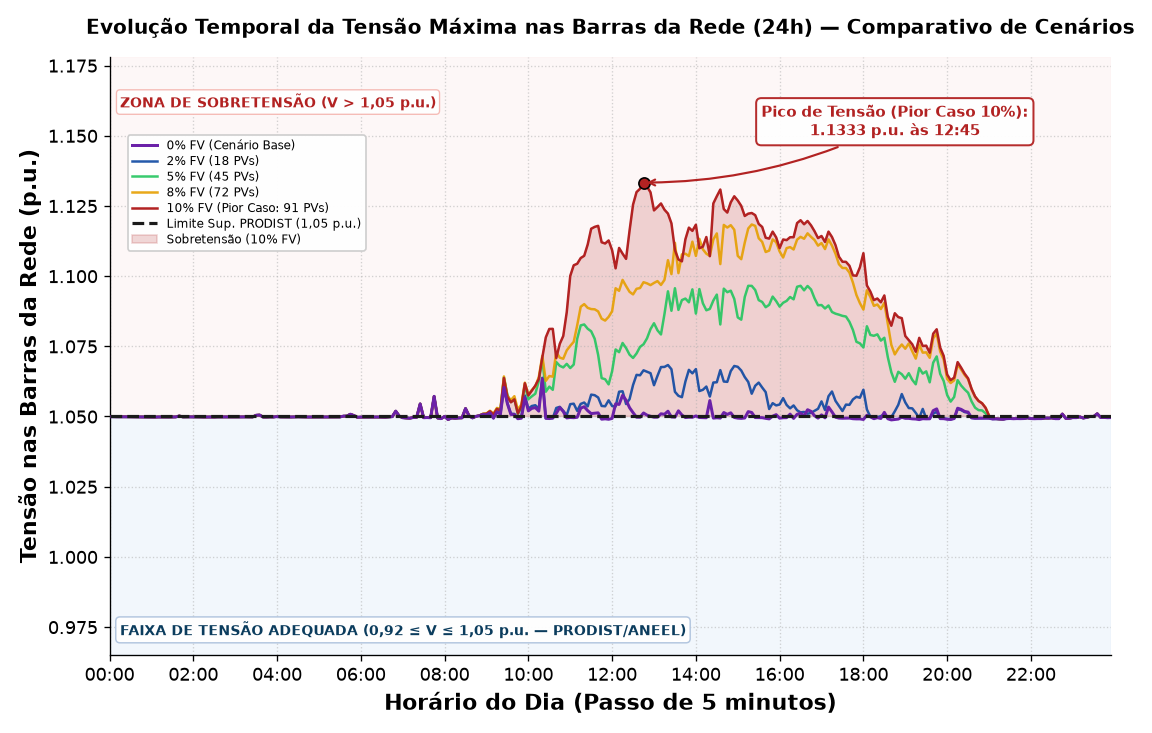

In [8]:
fig, ax = plt.subplots(figsize=TAMANHO_PADRAO)

meta_map = df_cenarios.set_index("pct_alvo").to_dict("index")

# 1. Faixas de fundo normativas PRODIST
# Zona de Tensão Adequada (0.965 a 1.05 p.u.)
ax.axhspan(0.965, 1.05, color="#EBF3FB", alpha=0.65, zorder=0)
# Zona de Sobretensão (> 1.05 p.u.)
ax.axhspan(1.05, 1.178, color="#FDF2F2", alpha=0.55, zorder=0)

# 2. Área preenchida de sobretensão no Pior Caso (10%) acima de 1.05 pu
v10_m = dados_cenarios[10]["v_max_t"]
h_sobr = ax.fill_between(
    timeline_24h,
    1.05,
    v10_m,
    where=(v10_m >= 1.05),
    color=COLORS["crimson"],
    alpha=0.18,
    zorder=1,
)

# 3. Curvas dos cenários — Estruturadas para garantir ordem na legenda de 0% a 10% (de cima para baixo)
LW_PADRAO = 1.5
cores_tensao = {
    2: "#0D47A1",  # Azul em tom mais escuro (Deep Navy)
    5: "#22C55E",  # Verde em tom mais claro (Vivid Light Green)
    8: COLORS["orange"],
}

handles_3a = []
labels_3a = []

# Curva Caso Base (0% FV) REFORÇADA E MAIS VISÍVEL (violeta intenso, linha contínua 1.8 pt, zorder=14)
v0_m = dados_cenarios[0]["v_max_t"]
l0, = ax.plot(
    timeline_24h,
    v0_m,
    linestyle="-",
    linewidth=1.8,
    color="#6B21A8",
    zorder=14,
)
handles_3a.append(l0)
labels_3a.append("0% FV (Cenário Base)")

# Curvas intermediárias (2%, 5%, 8% FV)
for pct in [2, 5, 8]:
    v_m = dados_cenarios[pct]["v_max_t"]
    meta = meta_map[pct]
    qtd = meta["qtd_pvs"]
    lp, = ax.plot(
        timeline_24h,
        v_m,
        linestyle="-",
        linewidth=LW_PADRAO,
        color=cores_tensao[pct],
        alpha=0.90,
        zorder=4,
    )
    handles_3a.append(lp)
    labels_3a.append(f"{pct}% FV ({qtd} PVs)")

# Curva Pior Caso (10% FV)
meta10 = meta_map[10]
qtd10 = meta10["qtd_pvs"]
l10, = ax.plot(
    timeline_24h,
    v10_m,
    linestyle="-",
    linewidth=LW_PADRAO,
    color=COLORS["crimson"],
    zorder=5,
)
handles_3a.append(l10)
labels_3a.append(f"10% FV (Pior Caso: {qtd10} PVs)")

# 4. LINHA DE LIMITE SUPERIOR DO PRODIST EM COR NEUTRA (Preto Carvão #1A1A1A) NA CAMADA SUPERIOR (zorder=15)
COR_PRODIST = "#1A1A1A"
l_prod = ax.axhline(
    1.05,
    color=COR_PRODIST,
    linewidth=1.9,
    linestyle="--",
    zorder=15,
)
handles_3a.append(l_prod)
labels_3a.append("Limite Sup. PRODIST (1,05 p.u.)")

# Sobretensão
handles_3a.append(h_sobr)
labels_3a.append("Sobretensão (10% FV)")

# 5. TEXTOS DAS ZONAS DE TENSÃO ALINHADOS COM OS EXTREMOS ESQUERDO SUPERIOR E INFERIOR
t_extremo = timeline_24h.iloc[3]  # 00:15
ax.text(
    t_extremo, 1.162,
    "ZONA DE SOBRETENSÃO (V > 1,05 p.u.)",
    ha="left", va="center",
    fontsize=8.5, fontweight="bold", color=COLORS["crimson"],
    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#F5B7B1", alpha=0.95, lw=0.8),
    zorder=16,
)

ax.text(
    t_extremo, 0.974,
    "FAIXA DE TENSÃO ADEQUADA (0,92 ≤ V ≤ 1,05 p.u. — PRODIST/ANEEL)",
    ha="left", va="center",
    fontsize=8.5, fontweight="bold", color=COLORS["navy"],
    bbox=dict(boxstyle="round,pad=0.30", facecolor="white", edgecolor="#B0C4DE", alpha=0.95, lw=0.9),
    zorder=16,
)

# 6. Marcador compacto e anotação do pico do Pior Caso movida para cima
max_idx = v10_m.idxmax()
t_max = timeline_24h.iloc[max_idx]
val_max = v10_m.iloc[max_idx]
hora_max = t_max.strftime("%H:%M")

ax.scatter(
    [t_max],
    [val_max],
    s=45,
    color=COLORS["crimson"],
    edgecolor="black",
    linewidth=1.0,
    zorder=17,
)

t_callout = timeline_24h.iloc[225]  # ~18:45
ax.annotate(
    f"Pico de Tensão (Pior Caso 10%):\n{val_max:.4f} p.u. às {hora_max}",
    xy=(t_max, val_max),
    xytext=(t_callout, 1.155),
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=-0.12",
        color=COLORS["crimson"],
        lw=1.3,
    ),
    ha="center",
    va="center",
    fontsize=8.8,
    fontweight="bold",
    color=COLORS["crimson"],
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor=COLORS["crimson"],
        alpha=0.95,
        lw=1.2,
    ),
    zorder=18,
)

# 7. Legenda posicionada no quadrante superior esquerdo com ordem estrita de 0% a 10%
leg = ax.legend(
    handles=handles_3a,
    labels=labels_3a,
    bbox_to_anchor=(0.012, 0.88),
    loc="upper left",
    fontsize=7.4,
    frameon=True,
    facecolor="#FFFFFF",
    edgecolor="#CCCCCC",
    framealpha=0.96,
    borderpad=0.35,
    labelspacing=0.22,
)
leg.set_zorder(20)

# Configurações de eixos e formatação temporal
ax.set_title(
    "Evolução Temporal da Tensão Máxima nas Barras da Rede (24h) — Comparativo de Cenários",
    fontsize=12.0,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("Horário do Dia (Passo de 5 minutos)")
ax.set_ylabel("Tensão nas Barras da Rede (p.u.)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.set_xlim(timeline_24h.iloc[0], timeline_24h.iloc[-1])
ax.set_ylim(0.965, 1.178)
ax.grid(True, linestyle=":", alpha=0.55, zorder=0)

plt.tight_layout()
salvar_figura_banner(fig, "fig3a_envelope_tensao_24h")
plt.show()

## 7. Figura 3b — Evolução Temporal da Tensão na Barra e Fase Mais Afetada (Barra 890 — Fase 2) — Comparativo de Cenários

Curvas diárias de tensão na barra e fase que sofrem a maior sobretensão de todo o alimentador (**Barra Crítica 890, Fase 2**, associada ao gerador FV81 de 10 kVA) ao longo de 24 horas, comparando todos os cenários de penetração (**0% Base, 2%, 5%, 8% e 10% Pior Caso**), com formatação e identidade visual alinhadas à Figura 3a:
- **Identificação da Fase Mais Crítica**: A Fase 2 da Barra 890 atinge o pico absoluto de toda a simulação ($1{,}1333\text{ p.u.}$ às 12h45 no Pior Caso de 10% FV) e apresenta a maior elevação pontual ($\Delta V = +0{,}0858\text{ p.u.}$ em relação ao Caso Base).
- **Camada Normativa Superior (PRODIST em Preto Carvão)**: Limite de tensão adequada ($1{,}05\text{ p.u.}$) renderizado em camada superior (`zorder=15`) em cor neutra (`#1A1A1A`), delimitando a *Faixa de Tensão Adequada* e a *Zona de Sobretensão*.
- **Destaque do Caso Base (0% FV em Violeta Intenso)**: Curva de tensão da fase sem geração fotovoltaica destacada em violeta intenso (`#6B21A8`, linha contínua 1.8 pt, `zorder=14`), demonstrando que no cenário passivo a tensão se mantém estritamente dentro da faixa adequada do PRODIST ($0{,}993\text{ p.u.}$ a $1{,}050\text{ p.u.}$).
- **Hierarquia da Legenda (0% a 10%)**: A legenda segue a ordem de penetração, de cima para baixo: 0%, 2%, 5%, 8% e 10% FV, seguida da referência do PRODIST.
- **Rótulos das Zonas e Callout de Pico**: Rótulos normativos alinhados à esquerda às 00h15 e anotação do pico absoluto de tensão posicionada na margem superior direita com marcador compacto.

[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig3b_tensao_barra_critica_890.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig3b_tensao_barra_critica_890.pdf


[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig3b_tensao_barra_critica_699.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig3b_tensao_barra_critica_699.pdf


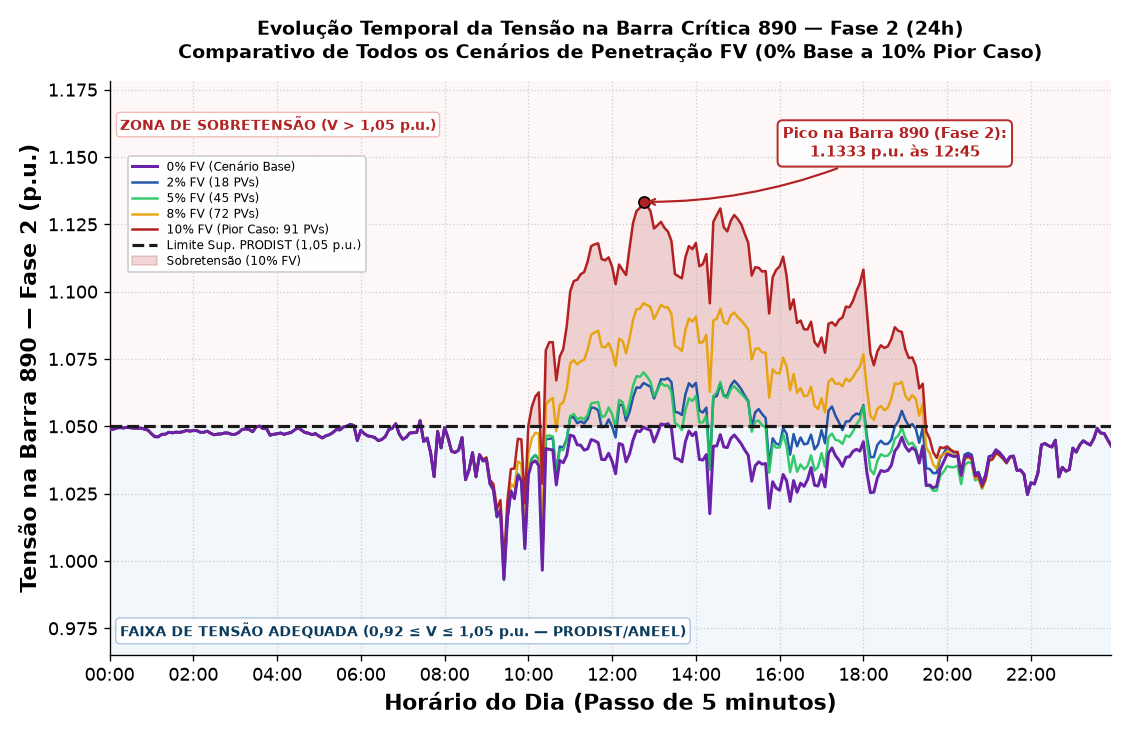

In [9]:
fig, ax = plt.subplots(figsize=TAMANHO_PADRAO)

meta_map = df_cenarios.set_index("pct_alvo").to_dict("index")

# Identificação dinâmica da barra e fase com maior sobretensão global
df10 = dados_cenarios[10]["df"]
v_cols10 = [
    c for c in df10.columns
    if c.endswith(("V1_pu", "V2_pu", "V3_pu")) and "sourcebus" not in c.lower()
]
col_crit = df10[v_cols10].max().idxmax()
v_max_global = float(df10[col_crit].max())

m_crit = re.search(r"Bus-(\d+)-V(\d)", col_crit)
barra_id = m_crit.group(1)
fase_id = m_crit.group(2)

# 1. Faixas de fundo normativas PRODIST
# Zona de Tensão Adequada (0.965 a 1.05 p.u.)
ax.axhspan(0.965, 1.05, color="#EBF3FB", alpha=0.65, zorder=0)
# Zona de Sobretensão (> 1.05 p.u.)
ax.axhspan(1.05, 1.178, color="#FDF2F2", alpha=0.55, zorder=0)

# 2. Área preenchida de sobretensão no Pior Caso (10%) acima de 1.05 pu
v10_crit = dados_cenarios[10]["df"][col_crit]
h_sobr_b = ax.fill_between(
    timeline_24h,
    1.05,
    v10_crit,
    where=(v10_crit >= 1.05),
    color=COLORS["crimson"],
    alpha=0.18,
    zorder=1,
)

# 3. Curvas dos cenários — Estruturadas para garantir ordem na legenda de 0% a 10% (de cima para baixo)
LW_PADRAO = 1.5
cores_tensao = {
    2: "#0D47A1",  # Azul em tom mais escuro (Deep Navy)
    5: "#22C55E",  # Verde em tom mais claro (Vivid Light Green)
    8: COLORS["orange"],
}

handles_3b = []
labels_3b = []

# Curva Caso Base (0% FV) REFORÇADA E MAIS VISÍVEL (violeta intenso, linha contínua 1.8 pt, zorder=14)
v0_crit = dados_cenarios[0]["df"][col_crit]
l0_b, = ax.plot(
    timeline_24h,
    v0_crit,
    linestyle="-",
    linewidth=1.8,
    color="#6B21A8",
    zorder=14,
)
handles_3b.append(l0_b)
labels_3b.append("0% FV (Cenário Base)")

# Curvas intermediárias (2%, 5%, 8% FV)
for pct in [2, 5, 8]:
    v_series = dados_cenarios[pct]["df"][col_crit]
    meta = meta_map[pct]
    qtd = meta["qtd_pvs"]
    lp_b, = ax.plot(
        timeline_24h,
        v_series,
        linestyle="-",
        linewidth=LW_PADRAO,
        color=cores_tensao[pct],
        alpha=0.90,
        zorder=4,
    )
    handles_3b.append(lp_b)
    labels_3b.append(f"{pct}% FV ({qtd} PVs)")

# Curva Pior Caso (10% FV)
meta10 = meta_map[10]
qtd10 = meta10["qtd_pvs"]
l10_b, = ax.plot(
    timeline_24h,
    v10_crit,
    linestyle="-",
    linewidth=LW_PADRAO,
    color=COLORS["crimson"],
    zorder=5,
)
handles_3b.append(l10_b)
labels_3b.append(f"10% FV (Pior Caso: {qtd10} PVs)")

# 4. LINHA DE LIMITE SUPERIOR DO PRODIST EM COR NEUTRA (Preto Carvão #1A1A1A) NA CAMADA SUPERIOR (zorder=15)
COR_PRODIST = "#1A1A1A"
l_prod_b = ax.axhline(
    1.05,
    color=COR_PRODIST,
    linewidth=1.9,
    linestyle="--",
    zorder=15,
)
handles_3b.append(l_prod_b)
labels_3b.append("Limite Sup. PRODIST (1,05 p.u.)")

# Sobretensão
handles_3b.append(h_sobr_b)
labels_3b.append("Sobretensão (10% FV)")

# 5. TEXTOS DAS ZONAS DE TENSÃO ALINHADOS COM OS EXTREMOS ESQUERDO SUPERIOR E INFERIOR
t_extremo = timeline_24h.iloc[3]  # 00:15
ax.text(
    t_extremo, 1.162,
    "ZONA DE SOBRETENSÃO (V > 1,05 p.u.)",
    ha="left", va="center",
    fontsize=8.5, fontweight="bold", color=COLORS["crimson"],
    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#F5B7B1", alpha=0.95, lw=0.8),
    zorder=16,
)

ax.text(
    t_extremo, 0.974,
    "FAIXA DE TENSÃO ADEQUADA (0,92 ≤ V ≤ 1,05 p.u. — PRODIST/ANEEL)",
    ha="left", va="center",
    fontsize=8.5, fontweight="bold", color=COLORS["navy"],
    bbox=dict(boxstyle="round,pad=0.30", facecolor="white", edgecolor="#B0C4DE", alpha=0.95, lw=0.9),
    zorder=16,
)

# 6. Marcador compacto e anotação do pico do Pior Caso movida para cima
max_idx = v10_crit.idxmax()
t_max = timeline_24h.iloc[max_idx]
val_max = v10_crit.iloc[max_idx]
hora_max = t_max.strftime("%H:%M")

ax.scatter(
    [t_max],
    [val_max],
    s=45,
    color=COLORS["crimson"],
    edgecolor="black",
    linewidth=1.0,
    zorder=17,
)

t_callout = timeline_24h.iloc[225]  # ~18:45
ax.annotate(
    f"Pico na Barra {barra_id} (Fase {fase_id}):\n{val_max:.4f} p.u. às {hora_max}",
    xy=(t_max, val_max),
    xytext=(t_callout, 1.155),
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=-0.12",
        color=COLORS["crimson"],
        lw=1.3,
    ),
    ha="center",
    va="center",
    fontsize=8.8,
    fontweight="bold",
    color=COLORS["crimson"],
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor=COLORS["crimson"],
        alpha=0.95,
        lw=1.2,
    ),
    zorder=18,
)

# 7. Legenda posicionada no quadrante superior esquerdo com ordem estrita de 0% a 10%
leg = ax.legend(
    handles=handles_3b,
    labels=labels_3b,
    bbox_to_anchor=(0.012, 0.88),
    loc="upper left",
    fontsize=7.4,
    frameon=True,
    facecolor="#FFFFFF",
    edgecolor="#CCCCCC",
    framealpha=0.96,
    borderpad=0.35,
    labelspacing=0.22,
)
leg.set_zorder(20)

# 8. Configurações de eixos e formatação temporal
ax.set_title(
    f"Evolução Temporal da Tensão na Barra Crítica {barra_id} — Fase {fase_id} (24h)\nComparativo de Todos os Cenários de Penetração FV (0% Base a 10% Pior Caso)",
    fontsize=11.5,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("Horário do Dia (Passo de 5 minutos)")
ax.set_ylabel(f"Tensão na Barra {barra_id} — Fase {fase_id} (p.u.)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.set_xlim(timeline_24h.iloc[0], timeline_24h.iloc[-1])
ax.set_ylim(0.965, 1.178)
ax.grid(True, linestyle=":", alpha=0.55, zorder=0)

plt.tight_layout()
salvar_figura_banner(fig, "fig3b_tensao_barra_critica_890")
salvar_figura_banner(fig, "fig3b_tensao_barra_critica_699")
plt.show()

## 8. Figura 4a — Perfil Longitudinal de Tensão vs. Distância da Subestação (12h30)

Tensão em cada uma das 906 barras da rede no instante de pico solar (**12h30**) em função da sua distância euclidiana à subestação TR1, comparando o Cenário Base (**0%**) com o Pior Caso (**10% FV**).

[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig4a_perfil_longitudinal_tensao.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig4a_perfil_longitudinal_tensao.pdf


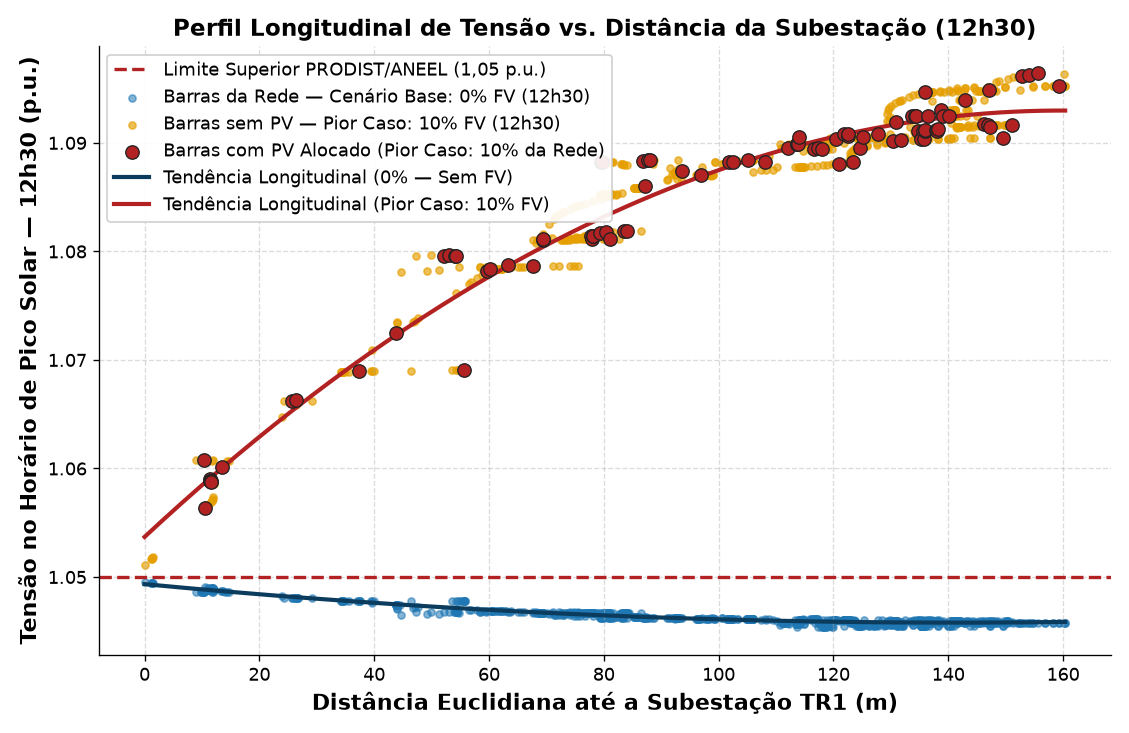

In [10]:
v_pico_0pct = dados_cenarios[0]["v_bus_pico"]
v_pico_worst = dados_cenarios[10]["v_bus_pico"]
pvs_buses_set = set(df_pvs["Barra"].astype(str))

rows_long = []
for bus_id, v0 in v_pico_0pct.items():
    if bus_id in coords_map and bus_id in v_pico_worst:
        v_w = v_pico_worst[bus_id]
        rows_long.append(
            {
                "Bus": bus_id,
                "Dist_m": coords_map[bus_id]["Dist_Sub_m"],
                "V_0pct": v0,
                "V_10pct": v_w,
                "Delta_V_pu": v_w - v0,
                "Tem_PV": bus_id in pvs_buses_set,
            }
        )
df_long = pd.DataFrame(rows_long).sort_values("Dist_m")

fig, ax = plt.subplots(figsize=TAMANHO_PADRAO)

ax.axhline(
    1.05,
    color=COLORS["crimson"],
    linestyle="--",
    linewidth=2.0,
    label="Limite Superior PRODIST/ANEEL (1,05 p.u.)",
)

ax.scatter(
    df_long["Dist_m"],
    df_long["V_0pct"],
    s=18,
    color=COLORS["blue"],
    alpha=0.55,
    label="Barras da Rede — Cenário Base: 0% FV (12h30)",
)
ax.scatter(
    df_long[~df_long["Tem_PV"]]["Dist_m"],
    df_long[~df_long["Tem_PV"]]["V_10pct"],
    s=18,
    color=COLORS["orange"],
    alpha=0.65,
    label="Barras sem PV — Pior Caso: 10% FV (12h30)",
)
ax.scatter(
    df_long[df_long["Tem_PV"]]["Dist_m"],
    df_long[df_long["Tem_PV"]]["V_10pct"],
    s=65,
    color=COLORS["crimson"],
    edgecolor="#222222",
    linewidth=0.8,
    zorder=4,
    label="Barras com PV Alocado (Pior Caso: 10% da Rede)",
)

# Curvas de tendência polinomial
z0 = np.poly1d(np.polyfit(df_long["Dist_m"], df_long["V_0pct"], 2))
z10 = np.poly1d(np.polyfit(df_long["Dist_m"], df_long["V_10pct"], 2))
d_grid = np.linspace(df_long["Dist_m"].min(), df_long["Dist_m"].max(), 200)
ax.plot(d_grid, z0(d_grid), color=COLORS["navy"], linewidth=2.5, label="Tendência Longitudinal (0% — Sem FV)")
ax.plot(d_grid, z10(d_grid), color=COLORS["crimson"], linewidth=2.5, label="Tendência Longitudinal (Pior Caso: 10% FV)")

ax.set_title("Perfil Longitudinal de Tensão vs. Distância da Subestação (12h30)")
ax.set_xlabel("Distância Euclidiana até a Subestação TR1 (m)")
ax.set_ylabel("Tensão no Horário de Pico Solar — 12h30 (p.u.)")
ax.legend(loc="upper left")

plt.tight_layout()
salvar_figura_banner(fig, "fig4a_perfil_longitudinal_tensao")
plt.show()

## 9. Figura 4b — Elevação Percentual de Tensão ($\Delta V\%$) ao Longo da Rede

Aumento percentual relativo de tensão ($\Delta V = V_{10\%} - V_{0\%}$) no horário de pico solar (12h30) em função da distância euclidiana à subestação TR1, evidenciando o acúmulo de sobretensão nos ramais terminais do Pior Caso Operativo.

[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig4b_elevacao_tensao_delta_v.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig4b_elevacao_tensao_delta_v.pdf


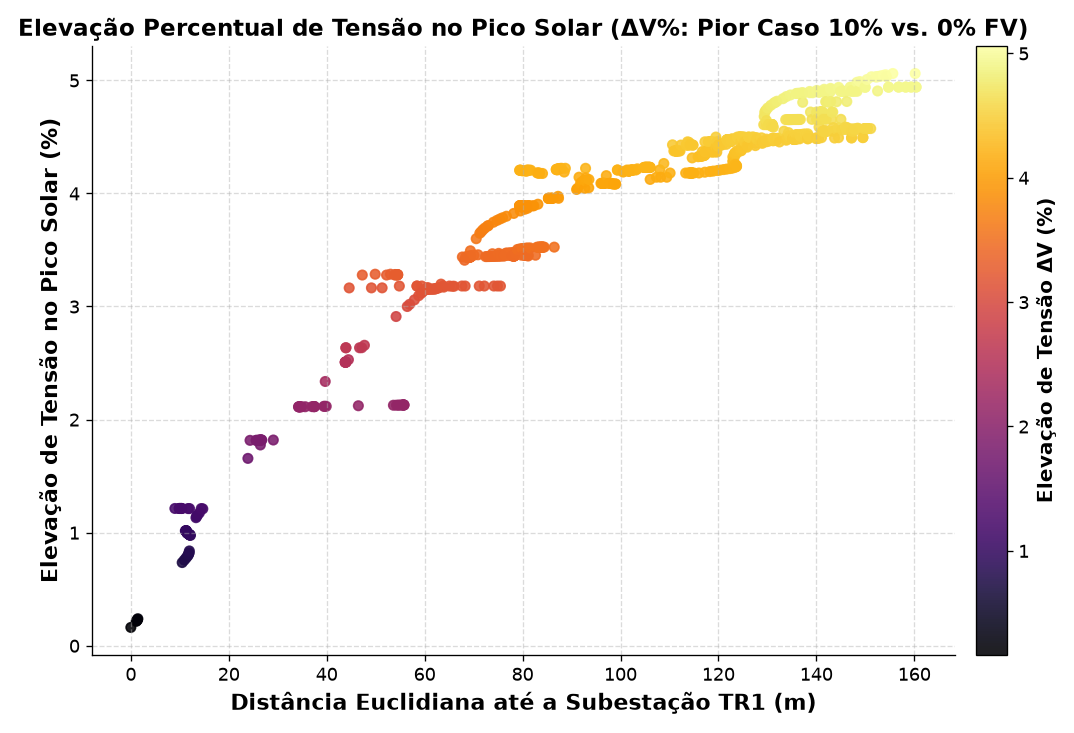

In [11]:
fig, ax = plt.subplots(figsize=TAMANHO_PADRAO)

sc_delta = ax.scatter(
    df_long["Dist_m"],
    df_long["Delta_V_pu"] * 100.0,
    c=df_long["Delta_V_pu"] * 100.0,
    cmap="inferno",
    s=32,
    alpha=0.88,
)
cbar_d = plt.colorbar(sc_delta, ax=ax, pad=0.02)
cbar_d.set_label("Elevação de Tensão ΔV (%)", fontsize=12, fontweight="bold")

ax.set_title("Elevação Percentual de Tensão no Pico Solar (ΔV%: Pior Caso 10% vs. 0% FV)")
ax.set_xlabel("Distância Euclidiana até a Subestação TR1 (m)")
ax.set_ylabel("Elevação de Tensão no Pico Solar (%)")

plt.tight_layout()
salvar_figura_banner(fig, "fig4b_elevacao_tensao_delta_v")
plt.show()

## 10. Figura 6 — Inversão do Fluxo de Potência no Alimentador Principal (`LINE1`) com Destaque ao Pior Caso (10%)

Curvas temporais de potência ativa medida na barra de saída do transformador abaixador TR1 (`LINE1`) ao longo do dia para as taxas de **0% (Base), 2%, 5%, 8% e 10% (Pior Caso)**, destacando a região em que $P_{\text{alimentador}} < 0$ (fluxo reverso da baixa para a média tensão).

[OK] Figura exportada:
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig6_inversao_fluxo_potencia.png
  -> /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/fig6_inversao_fluxo_potencia.pdf


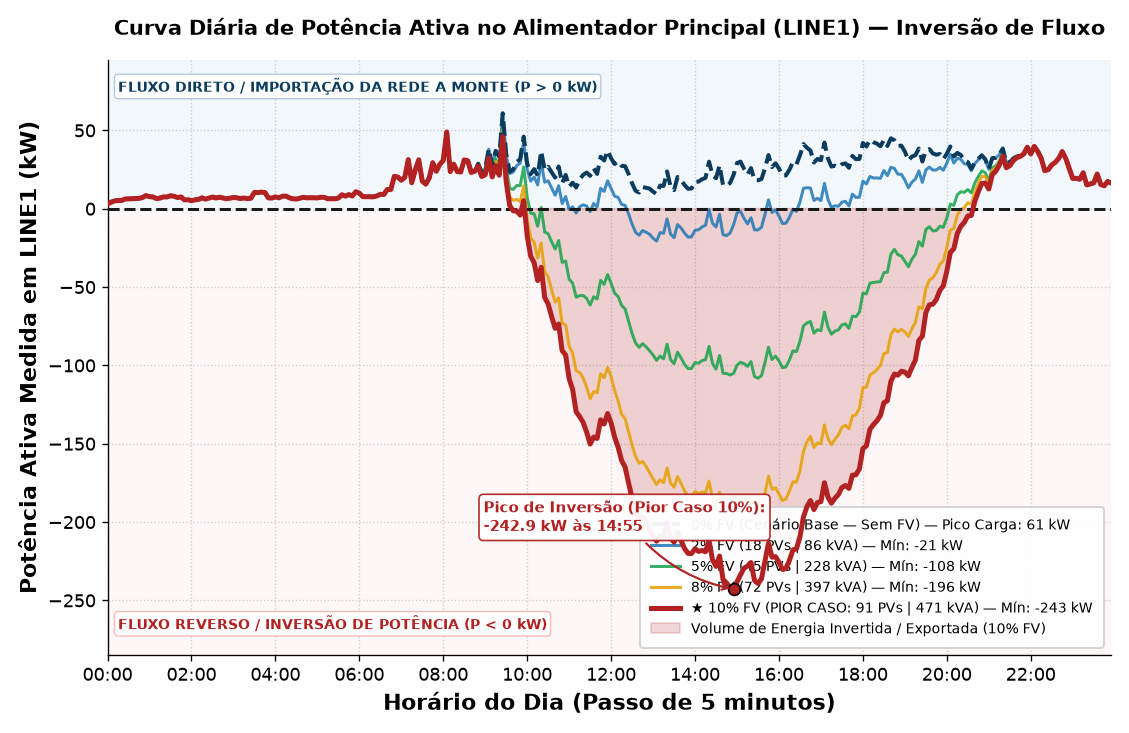

In [12]:
fig, ax = plt.subplots(figsize=TAMANHO_PADRAO)

meta_map = df_cenarios.set_index("pct_alvo").to_dict("index")

# 1. Faixas de operação de fluxo de potência
ax.axhspan(0, 95, color="#EBF3FB", alpha=0.65, zorder=0)
ax.axhspan(-285, 0, color="#FDF2F2", alpha=0.55, zorder=0)

# Linha divisória de fluxo nulo (0 kW)
ax.axhline(0, color="#1A1A1A", linewidth=1.8, linestyle="--", zorder=4)

# 2. Rótulos das zonas alinhados aos extremos esquerdos
ax.text(
    timeline_24h.iloc[3], -265,
    "FLUXO REVERSO / INVERSÃO DE POTÊNCIA (P < 0 kW)",
    ha="left", va="center", fontsize=8.5, fontweight="bold", color=COLORS["crimson"],
    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#F5B7B1", alpha=0.95, lw=0.8),
    zorder=5
)
ax.text(
    timeline_24h.iloc[3], 78,
    "FLUXO DIRETO / IMPORTAÇÃO DA REDE A MONTE (P > 0 kW)",
    ha="left", va="center", fontsize=8.5, fontweight="bold", color=COLORS["navy"],
    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#B0C4DE", alpha=0.95, lw=0.8),
    zorder=5
)

cores_fluxo = {
    0: COLORS["navy"],
    2: COLORS["blue"],
    5: COLORS["cyan"],
    8: COLORS["orange"],
    10: COLORS["crimson"],
}

handles_6 = []
labels_6 = []

# Curva Base (0% FV) destacada em tracejado escuro — Primeiro na legenda
p_0pct = dados_cenarios[0]["P_feeder_kW"]
l0_6, = ax.plot(
    timeline_24h, p_0pct,
    linestyle="--", linewidth=2.4, color=COLORS["navy"],
    zorder=4
)
handles_6.append(l0_6)
labels_6.append(f"0% FV (Cenário Base — Sem FV) — Pico Carga: {p_0pct.max():.0f} kW")

# Curvas intermediárias (2%, 5%, 8% FV)
for pct in [2, 5, 8]:
    p_kw = dados_cenarios[pct]["P_feeder_kW"]
    meta = meta_map[pct]
    qtd = meta["qtd_pvs"]
    kva = meta["kva_total"]
    lp_6, = ax.plot(
        timeline_24h, p_kw,
        linestyle="-", linewidth=1.8, color=cores_fluxo[pct], alpha=0.85,
        zorder=3
    )
    handles_6.append(lp_6)
    labels_6.append(f"{pct}% FV ({qtd} PVs | {kva:.0f} kVA) — Mín: {p_kw.min():.0f} kW")

# Curva Pior Caso (10% FV) em destaque absoluto
p_10pct = dados_cenarios[10]["P_feeder_kW"]
meta_10 = meta_map[10]
qtd_10 = meta_10["qtd_pvs"]
kva_10 = meta_10["kva_total"]
l10_6, = ax.plot(
    timeline_24h, p_10pct,
    linestyle="-", linewidth=3.0, color=COLORS["crimson"],
    zorder=6
)
handles_6.append(l10_6)
labels_6.append(f"★ 10% FV (PIOR CASO: {qtd_10} PVs | {kva_10:.0f} kVA) — Mín: {p_10pct.min():.0f} kW")

# Área preenchida do fluxo reverso no Pior Caso (10%)
h_rev = ax.fill_between(
    timeline_24h, 0, p_10pct,
    where=(p_10pct < 0),
    color=COLORS["crimson"], alpha=0.18, zorder=2,
)
handles_6.append(h_rev)
labels_6.append("Volume de Energia Invertida / Exportada (10% FV)")

# Marcador compacto e anotação do ponto crítico do Pior Caso
min_idx = p_10pct.idxmin()
t_min = timeline_24h.iloc[min_idx]
val_min = p_10pct.iloc[min_idx]
hora_min = t_min.strftime("%H:%M")

ax.scatter([t_min], [val_min], s=50, color=COLORS["crimson"], edgecolor="black", linewidth=1.0, zorder=7)
ax.annotate(
    f"Pico de Inversão (Pior Caso 10%):\n{val_min:.1f} kW às {hora_min}",
    xy=(t_min, val_min),
    xytext=(-150, 35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.2", color=COLORS["crimson"], lw=1.3),
    fontsize=9.0, fontweight="bold", color=COLORS["crimson"],
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=COLORS["crimson"], alpha=0.95, lw=1.0),
    zorder=8
)

# Configurações de eixos e formatação temporal
ax.set_title("Curva Diária de Potência Ativa no Alimentador Principal (LINE1) — Inversão de Fluxo", fontsize=12.5, fontweight="bold", pad=15)
ax.set_xlabel("Horário do Dia (Passo de 5 minutos)")
ax.set_ylabel("Potência Ativa Medida em LINE1 (kW)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.set_xlim(timeline_24h.iloc[0], timeline_24h.iloc[-1])
ax.set_ylim(-285, 95)
ax.grid(True, linestyle=":", alpha=0.6, zorder=1)

# Legenda com ordem estrita de 0% a 10%
ax.legend(
    handles=handles_6,
    labels=labels_6,
    loc="lower right",
    fontsize=8.5,
    frameon=True,
    facecolor="#FFFFFF",
    edgecolor="#CCCCCC",
    framealpha=0.95,
    borderpad=0.8,
    labelspacing=0.45
)

plt.tight_layout()
salvar_figura_banner(fig, "fig6_inversao_fluxo_potencia")
plt.show()

## 11. Tabela-Síntese de Indicadores por Porcentagem de Penetração FV para o Banner Acadêmico

Consolidação numérica dos indicadores operacionais para os níveis de penetração (**0%, 2%, 5%, 8% e 10%**), evidenciando o contraste entre a operação normal sem geração distribuída (**0%**) e a severidade operativa no **Pior Caso (10% das barras da rede com geração FV)**.

In [13]:
tabela_banner = []
for pct in niveis_pct:
    d = dados_cenarios[pct]
    meta = meta_map[pct]
    v_vals = np.array(list(d["v_bus_pico"].values()))
    p_min = float(d["P_feeder_kW"].min())
    rotulo_cenario = f"{pct}% ({meta['pct_efetivo']:.2f}%)" if pct != 10 else f"{pct}% (PIOR CASO)"
    tabela_banner.append(
        {
            "Penetração na Rede (%)": rotulo_cenario,
            "Barras com FV (Qtd / Total)": f"{meta['qtd_pvs']} / {TOTAL_BARRAS_REDE}",
            "Potência FV Instalada (kVA)": round(float(meta["kva_total"]), 1),
            "Tensão Média no Pico (p.u.)": round(float(v_vals.mean()), 4),
            "Tensão P95 no Pico (p.u.)": round(float(np.percentile(v_vals, 95)), 4),
            "Tensão Máxima no Pico (p.u.)": round(float(v_vals.max()), 4),
            "Barras > 1,05 p.u. (%)": round(float(100.0 * np.mean(v_vals > 1.05)), 2),
            "Potência Mín. Alimentador LINE1 (kW)": round(p_min, 1),
            "Inversão de Fluxo": "Sim" if p_min < 0 else "Não",
        }
    )

df_resumo_banner = pd.DataFrame(tabela_banner)
df_resumo_banner.to_csv(BANNER_FIG_DIR / "tabela_sintese_banner.csv", index=False)
print("=" * 85)
print("TABELA-SÍNTESE CONSOLIDADA DOS CENÁRIOS PARA O BANNER CIENTÍFICO")
print("=" * 85)
display(df_resumo_banner)
print(f"\nTabela exportada em: {BANNER_FIG_DIR / 'tabela_sintese_banner.csv'}")

TABELA-SÍNTESE CONSOLIDADA DOS CENÁRIOS PARA O BANNER CIENTÍFICO


,Penetração na Rede (%),Barras com FV (Qtd / Total),Potência FV Instalada (kVA),Tensão Média no Pico (p.u.),Tensão P95 no Pico (p.u.),Tensão Máxima no Pico (p.u.),"Barras > 1,05 p.u. (%)",Potência Mín. Alimentador LINE1 (kW),Inversão de Fluxo
0,0% (0.00%),0 / 906,0.0,1.0463,1.0486,1.0495,0.00,3.0,Não
1,2% (1.99%),18 / 906,86.5,1.0505,1.0508,1.0508,97.35,-20.7,Sim
2,5% (4.97%),45 / 906,228.2,1.0648,1.0679,1.0682,100.00,-108.3,Sim
3,8% (7.95%),72 / 906,396.9,1.0786,1.0848,1.0856,100.00,-195.9,Sim
4,10% (PIOR CASO),91 / 906,470.7,1.0853,1.0948,1.0964,100.00,-242.9,Sim



Tabela exportada em: /mnt/c/Users/pvict/OneDrive/EU-2026-lv-test-case-pv-creator/output/figuras_banner/tabela_sintese_banner.csv
